# 01 · Explore the raw trips

**Goal:** understand the January 2025 Yellow Taxi data well enough to decide three things before any model is trained:

1. which trips are plausible enough to learn from (the cleaning rule),
2. which columns the model may use (only what is known when a trip is booked),
3. how to split training and validation data.

The reusable logic lives in `src/trip_duration/` and is imported here, so this notebook explores and explains, and the package does the work.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from trip_duration import config, data, features

pd.set_option("display.float_format", "{:,.2f}".format)
IMAGES = config.PROJECT_ROOT / "docs" / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

# Chart style: one blue for data, orange for rule lines, quiet grid.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
    }
)

## The raw file

In [2]:
raw = data.load_trips()
print(f"{len(raw):,} trips, {raw.shape[1]} columns")
raw.head()

3,475,226 trips, 20 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.00,1.60,1.00,N,229,237,1,10.00,3.50,0.50,3.00,0.00,1.00,18.00,2.50,0.00,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.00,0.50,1.00,N,236,237,1,5.10,3.50,0.50,2.02,0.00,1.00,12.12,2.50,0.00,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.00,0.60,1.00,N,141,141,1,5.10,3.50,0.50,2.00,0.00,1.00,12.10,2.50,0.00,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.00,0.52,1.00,N,244,244,2,7.20,1.00,0.50,0.00,0.00,1.00,9.70,0.00,0.00,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.00,0.66,1.00,N,244,116,2,5.80,1.00,0.50,0.00,0.00,1.00,8.30,0.00,0.00,0.00


In [3]:
raw.dtypes.to_frame("dtype").T

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
dtype,int32,datetime64[us],datetime64[us],float64,float64,float64,str,int32,int32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


## Which columns may the model use?

The API is called **when a trip is booked**, before it happens. Anything only known after the ride would leak the answer into the model: it would score well here and be useless in production.

In [4]:
column_roles = pd.DataFrame(
    {
        "known at booking?": {
            "PULocationID": "yes (pickup zone)",
            "DOLocationID": "yes (destination zone)",
            "trip_distance": "only as a plan: training uses the distance driven (see README Limitations)",
            "tpep_pickup_datetime": "yes (hour and weekday)",
            "passenger_count": "yes, but 15.5% missing",
            "fare_amount, tip_amount, tolls_amount, total_amount": "no, set after the trip",
            "payment_type": "no, chosen at the end",
            "tpep_dropoff_datetime": "no, it IS the answer",
        }
    }
)
column_roles

,known at booking?
PULocationID,yes (pickup zone)
DOLocationID,yes (destination zone)
trip_distance,only as a plan: training uses the distance dri...
tpep_pickup_datetime,yes (hour and weekday)
passenger_count,"yes, but 15.5% missing"
"fare_amount, tip_amount, tolls_amount, total_amount","no, set after the trip"
payment_type,"no, chosen at the end"
tpep_dropoff_datetime,"no, it IS the answer"


In [5]:
print(f"passenger_count missing: {raw['passenger_count'].isna().mean():.1%}")

passenger_count missing: 15.5%


## Target: trip duration

Duration is dropoff time minus pickup time, in minutes. The raw values include impossible trips (negative, or several days).

In [6]:
trips = features.add_duration(raw)
trips[config.TARGET].describe(
    percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
).to_frame().T

,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
duration_minutes,"3,475,226.00",15.02,38.71,"-51,472.32",0.07,0.67,3.37,11.70,36.20,58.92,98.26,"5,626.32"


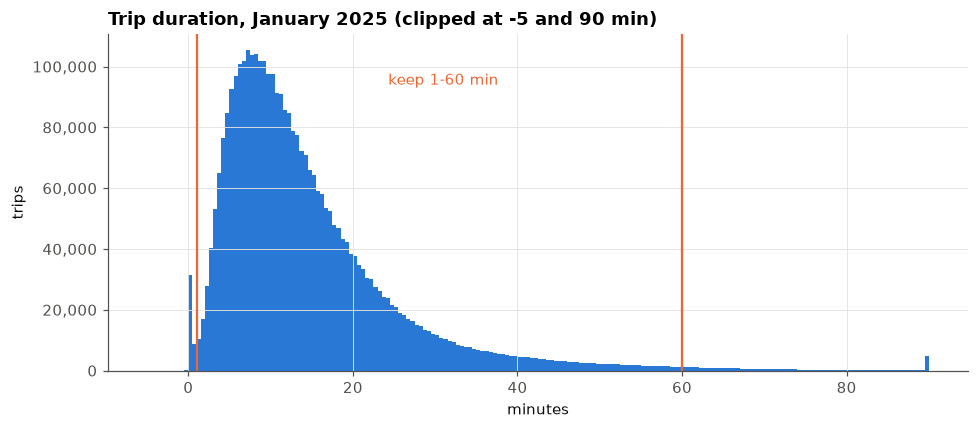

In [7]:
fig, ax = plt.subplots()
trips[config.TARGET].clip(-5, 90).plot.hist(
    bins=190, ax=ax, color=BLUE, edgecolor="none"
)
for bound in (config.MIN_DURATION_MINUTES, config.MAX_DURATION_MINUTES):
    ax.axvline(bound, color=ORANGE, linewidth=1.5)
ax.set(
    title="Trip duration, January 2025 (clipped at -5 and 90 min)",
    xlabel="minutes",
    ylabel="trips",
)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.annotate(
    "keep 1-60 min", xy=(31, ax.get_ylim()[1] * 0.85), color=ORANGE, ha="center"
)
fig.tight_layout()
fig.savefig(IMAGES / "duration_histogram.png")

In [8]:
share_kept = (
    trips[config.TARGET]
    .between(config.MIN_DURATION_MINUTES, config.MAX_DURATION_MINUTES)
    .mean()
)
print(f"Trips between 1 and 60 minutes: {share_kept:.1%}")

Trips between 1 and 60 minutes: 97.9%


Almost all trips (98%) last between 1 and 60 minutes. Trips under 1 minute are likely cancelled or mis-recorded, and the long tail above 60 minutes likely includes meters left running. Keeping 1-60 minutes is the course's standard rule, and the histogram supports it.

## Distance

In [9]:
trips["trip_distance"].describe(
    percentiles=[0.01, 0.026, 0.5, 0.99, 0.9999]
).to_frame().T

,count,mean,std,min,1%,2.6%,50%,99%,99.99%,max
trip_distance,"3,475,226.00",5.86,564.60,0.00,0.00,0.00,1.67,19.50,58.42,"276,423.57"


In [10]:
print(f"Zero-distance trips: {(trips['trip_distance'] == 0).mean():.1%}")
print(f"Trips over 100 miles: {(trips['trip_distance'] > 100).sum():,}")

Zero-distance trips: 2.6%
Trips over 100 miles: 162


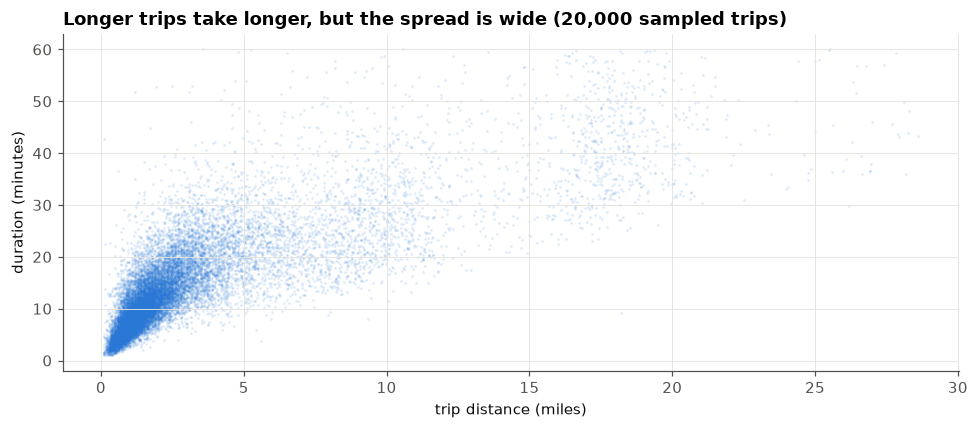

In [11]:
sample = trips[
    trips[config.TARGET].between(1, 60) & trips["trip_distance"].between(0.1, 30)
].sample(20_000, random_state=config.RANDOM_STATE)
fig, ax = plt.subplots()
ax.scatter(
    sample["trip_distance"],
    sample[config.TARGET],
    s=3,
    alpha=0.15,
    color=BLUE,
    linewidths=0,
)
ax.set(
    title="Longer trips take longer, but the spread is wide (20,000 sampled trips)",
    xlabel="trip distance (miles)",
    ylabel="duration (minutes)",
)
fig.tight_layout()
fig.savefig(IMAGES / "distance_vs_duration.png")

Distance is the strongest single signal, but the same 3 miles can take 10 or 40 minutes. That spread is what the time features should explain.

## Time of day and weekday

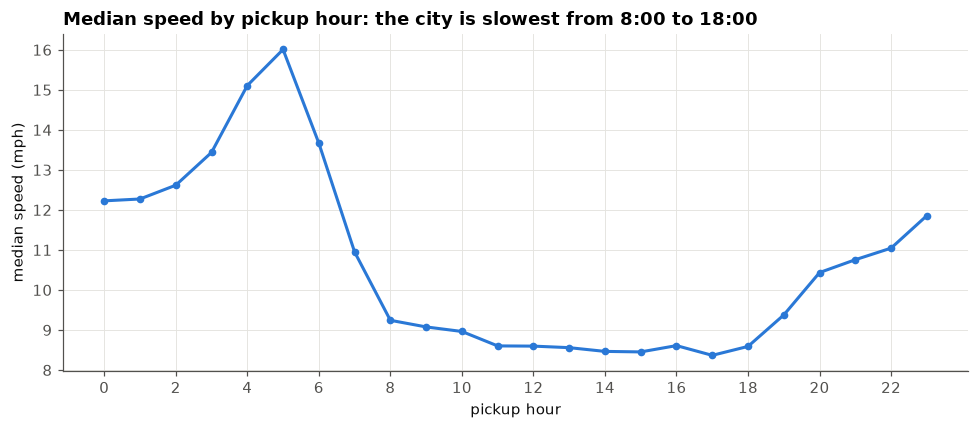

In [12]:
clean_preview = trips[trips[config.TARGET].between(1, 60)]
pickup = clean_preview[config.PICKUP_TIME]
speed = (clean_preview["trip_distance"] / (clean_preview[config.TARGET] / 60)).clip(
    upper=60
)
by_hour = speed.groupby(pickup.dt.hour).median()

fig, ax = plt.subplots()
ax.plot(
    by_hour.index, by_hour.values, color=BLUE, linewidth=2, marker="o", markersize=4
)
ax.set(
    title="Median speed by pickup hour: the city is slowest from 8:00 to 18:00",
    xlabel="pickup hour",
    ylabel="median speed (mph)",
    xticks=range(0, 24, 2),
)
fig.tight_layout()
fig.savefig(IMAGES / "speed_by_hour.png")

In [13]:
by_weekday = speed.groupby(pickup.dt.day_of_week).median()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday.to_frame("median mph").T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
median mph,10.11,9.09,9.33,8.92,8.98,9.85,11.16


Speed (miles per hour) is used here instead of duration so that distance doesn't hide the effect. The same trip takes far longer at 17:00 on a Thursday than at 05:00 on a Sunday, so **pickup hour and weekday** become features. Both are known at booking.

## Cleaning rule: how many trips each step removes

The rules are applied in order by `features.filter_outliers`. The table shows what each one costs.

In [14]:
steps = [
    ("raw file", pd.Series(True, index=trips.index)),
    (
        "duration 1-60 min",
        trips[config.TARGET].between(
            config.MIN_DURATION_MINUTES, config.MAX_DURATION_MINUTES
        ),
    ),
    (
        "distance 0.1-100 miles",
        trips["trip_distance"].between(
            config.MIN_DISTANCE_MILES, config.MAX_DISTANCE_MILES
        ),
    ),
    (
        "valid pickup and dropoff zones (1-265)",
        trips["PULocationID"].between(config.MIN_ZONE_ID, config.MAX_ZONE_ID)
        & trips["DOLocationID"].between(config.MIN_ZONE_ID, config.MAX_ZONE_ID),
    ),
    (
        "pickup inside January 2025",
        (trips[config.PICKUP_TIME] >= config.PERIOD_START)
        & (trips[config.PICKUP_TIME] < config.PERIOD_END),
    ),
]
keep = pd.Series(True, index=trips.index)
rows = []
for name, rule in steps:
    before = keep.sum()
    keep &= rule
    rows.append(
        {"step": name, "trips left": keep.sum(), "removed": before - keep.sum()}
    )
funnel = pd.DataFrame(rows)
funnel["share left"] = (funnel["trips left"] / len(trips)).map("{:.1%}".format)
funnel.style.format({"trips left": "{:,}", "removed": "{:,}"}).hide(axis="index")

step,trips left,removed,share left
raw file,"3,475,226",0,100.0%
duration 1-60 min,"3,403,248","71,978",97.9%
distance 0.1-100 miles,"3,325,893","77,355",95.7%
valid pickup and dropoff zones (1-265),"3,325,893",0,95.7%
pickup inside January 2025,"3,325,872",21,95.7%


In [15]:
clean = features.filter_outliers(trips)
assert len(clean) == keep.sum(), "the package's filter must match the funnel above"
print(f"{len(clean):,} clean trips")

3,325,872 clean trips


## Train / validation split by date

The service will predict trips that haven't happened yet. So the model learns from **1-21 January** and is judged on **22-31 January**. A random split would put trips from the same rush hour in both sets and flatter the score.

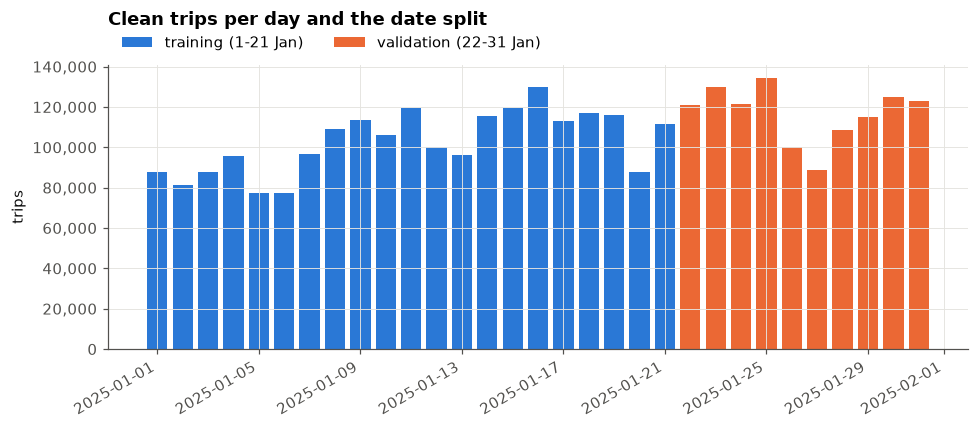

In [16]:
daily = clean.groupby(clean[config.PICKUP_TIME].dt.date).size()
is_val = pd.to_datetime(daily.index) >= config.VALIDATION_START
fig, ax = plt.subplots()
ax.bar(
    daily.index[~is_val],
    daily.values[~is_val],
    color=BLUE,
    label="training (1-21 Jan)",
    width=0.8,
)
ax.bar(
    daily.index[is_val],
    daily.values[is_val],
    color=ORANGE,
    label="validation (22-31 Jan)",
    width=0.8,
)
ax.set(title="Clean trips per day and the date split", ylabel="trips")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title("Clean trips per day and the date split", pad=26)
ax.yaxis.set_major_formatter("{x:,.0f}")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(IMAGES / "date_split.png")

In [17]:
train, val = features.split_by_date(clean)
print(
    f"training: {len(train):,} trips | validation: {len(val):,} trips ({len(val) / len(clean):.0%})"
)

training: 2,158,857 trips | validation: 1,167,015 trips (35%)


## What this decides

| Finding | Decision |
|---|---|
| 98% of trips last 1-60 minutes; the rest are mostly errors | Keep 1-60 minutes |
| 2.6% of trips have zero distance; a few claim hundreds of miles | Keep 0.1-100 miles |
| Fare, tip and total are only known after the trip | Never used as features |
| Speed drops sharply 8:00-18:00 and on weekdays | Add pickup hour and weekday |
| The API predicts future trips | Validate on 22-31 January |

Next step: `uv run trip-duration train` compares models on exactly these sets and logs every run to MLflow.